In [ ]:
#loading importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy as sp


In [5]:
#Load the Dataset
df = pd.read_csv("../Data/netflix_titles.csv")

In [6]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [7]:
 # displaying the data types
df.dtypes

show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   object
 10  listed_in     7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(1), object(11)
memory usage: 730.2+ KB


In [9]:
df.shape  #7787 records and 12 columns

(7787, 12)

In [10]:
df.isnull().sum()  # sum of null values

show_id            0
type               0
title              0
director        2389
cast             718
country          507
date_added        10
release_year       0
rating             7
duration           0
listed_in          0
description        0
dtype: int64

In [11]:
#percentage of null values
df.isnull().sum()/(len(df))*100

show_id          0.000000
type             0.000000
title            0.000000
director        30.679337
cast             9.220496
country          6.510851
date_added       0.128419
release_year     0.000000
rating           0.089893
duration         0.000000
listed_in        0.000000
description      0.000000
dtype: float64

In [12]:
director=df.dropna(axis=1)

In [13]:
df.date_added.fillna("unknown",inplace= True)

In [14]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2389
cast             718
country          507
date_added         0
release_year       0
rating             7
duration           0
listed_in          0
description        0
dtype: int64

In [15]:
#creating new year column from date_added column
df["year"]= df.date_added.apply(lambda x: str(x).split(",")[-1])

In [16]:
#most occuring date:2019
df.year.value_counts()    #COUNTING THE VALUES USING VALUE_COUNTS()

year
 2019      2153
 2020      2009
 2018      1685
 2017      1225
 2016       443
 2021       117
 2015        88
 2014        25
 2011        13
 2013        11
unknown      10
 2012         3
 2008         2
 2009         2
 2010         1
Name: count, dtype: int64

In [17]:
#replacing unknown values with 2019(most occuring date year)
df["year"]= df.year.apply(lambda x: str(x).replace("unknown","2019"))

In [18]:
#removing extra space in the year column values
df["year"]= df.year.apply(lambda x: str(x).replace(" ",""))

In [19]:
df.year.value_counts()

year
2019    2163
2020    2009
2018    1685
2017    1225
2016     443
2021     117
2015      88
2014      25
2011      13
2013      11
2012       3
2008       2
2009       2
2010       1
Name: count, dtype: int64

In [20]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2389
cast             718
country          507
date_added         0
release_year       0
rating             7
duration           0
listed_in          0
description        0
year               0
dtype: int64

In [21]:
df.country.value_counts() #displaying the most occurred country

country
United States                                                   2555
India                                                            923
United Kingdom                                                   397
Japan                                                            226
South Korea                                                      183
                                                                ... 
Russia, United States, China                                       1
Italy, Switzerland, France, Germany                                1
United States, United Kingdom, Canada                              1
United States, United Kingdom, Japan                               1
Sweden, Czech Republic, United Kingdom, Denmark, Netherlands       1
Name: count, Length: 681, dtype: int64

In [22]:
#filling null values of country with most occuring country
df.country.fillna("United_states",inplace= True)

In [23]:
df.rating.value_counts()   #displaying the most occurred rating

rating
TV-MA       2863
TV-14       1931
TV-PG        806
R            665
PG-13        386
TV-Y         280
TV-Y7        271
PG           247
TV-G         194
NR            84
G             39
TV-Y7-FV       6
UR             5
NC-17          3
Name: count, dtype: int64

In [24]:
#filling null values of rating with most occuring rating
df.rating.fillna("TV-MA",inplace= True)

In [25]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2389
cast             718
country            0
date_added         0
release_year       0
rating             0
duration           0
listed_in          0
description        0
year               0
dtype: int64

Text(0, 0.5, 'Number of country')

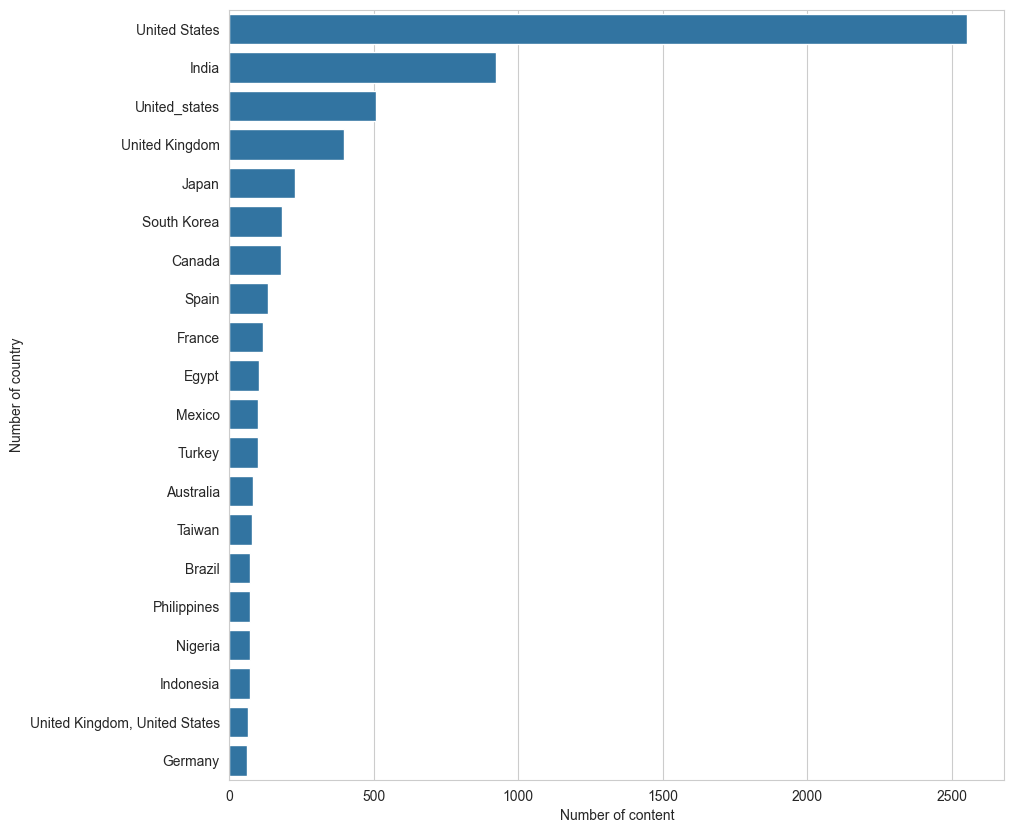

In [28]:
# displaying all the countries with most contribution to netflix content
x= df.country.value_counts().head(20)
plt.figure(figsize=(10,10))
sns.set_style("whitegrid")   #set style to whitegrid
ax= sns.barplot(x=x.values, y=x.index)   #using bar for visualization
ax.set_xlabel("Number of content")
ax.set_ylabel("Number of country")

<Axes: xlabel='type', ylabel='count'>

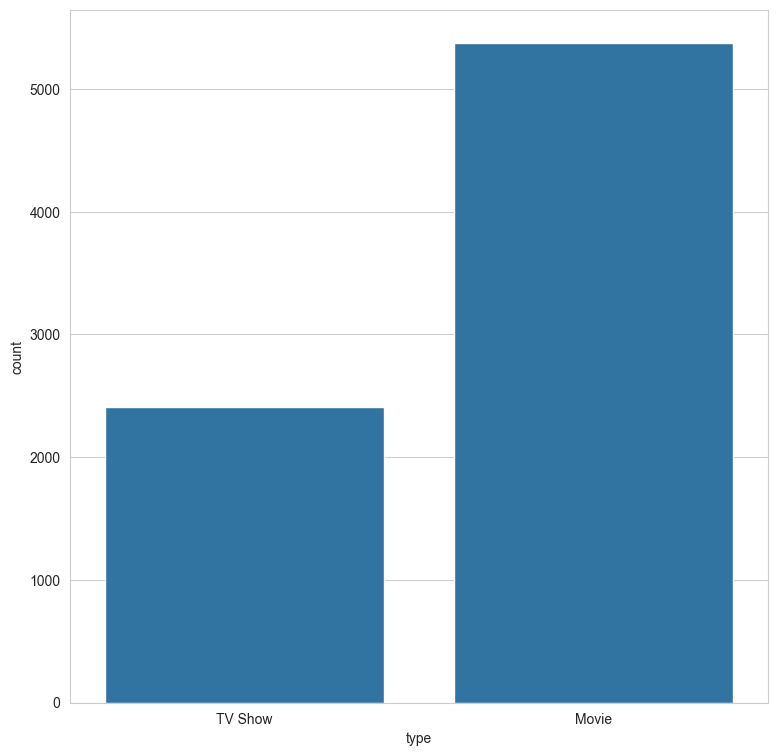

In [29]:

plt.figure(figsize=(9,9))

x= df.type.value_counts()
sns.countplot(x= "type",data= df)

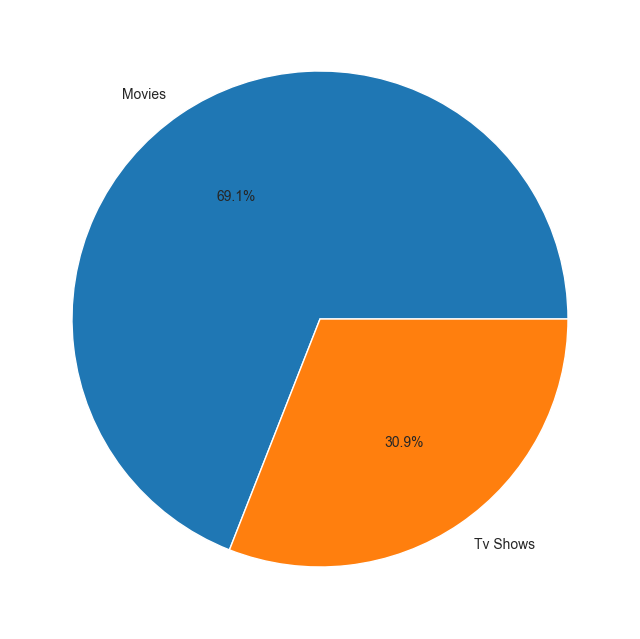

In [30]:
plt.figure(figsize=(8,10))

label= ["Movies","Tv Shows"]

plt.pie(x.values, labels= label ,autopct= "%1.1f%%") # visualizing using pie
plt.show()   

<Axes: xlabel='Year'>

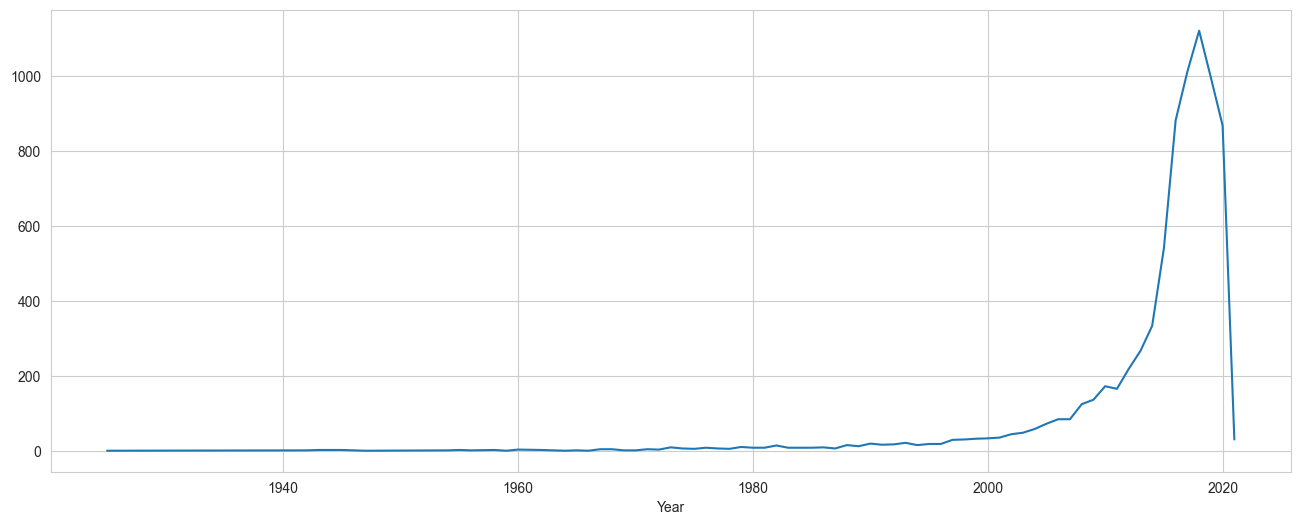

In [31]:
#Netflix content releases over the years
x= df.release_year.value_counts()
plt.figure(figsize=(16,6))
plt.xlabel("Year")

sns.lineplot(x=x.index ,y= x.values)

Text(0, 0.5, 'No of content')

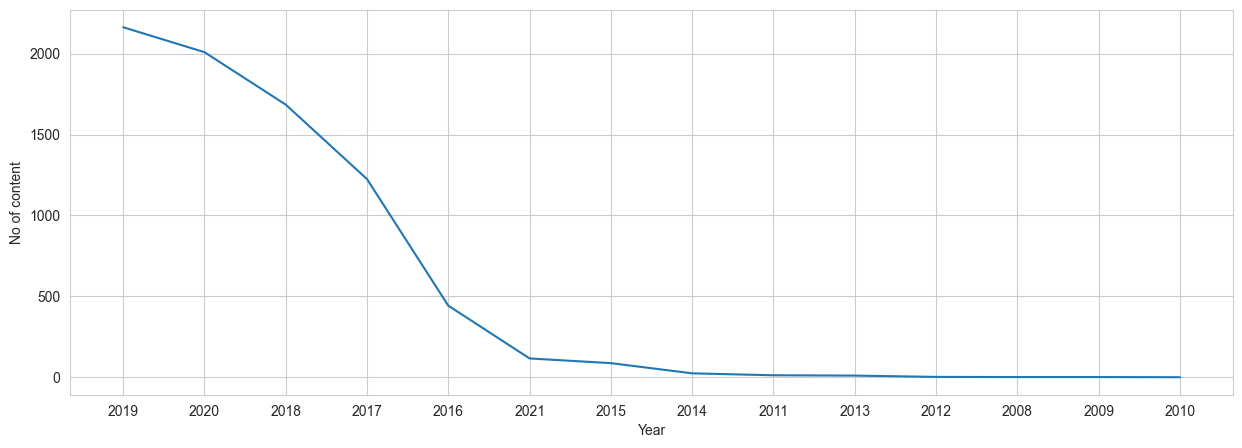

In [33]:
#Number of content added on netflix over the years
plt.figure(figsize=(15,5))
x= df.year.value_counts()
ax = sns.lineplot(x=x.index, y=x.values)
ax.set_xlabel("Year")
ax.set_ylabel("No of content")
ax.set_ylabel("No of content")

<Axes: ylabel='year'>

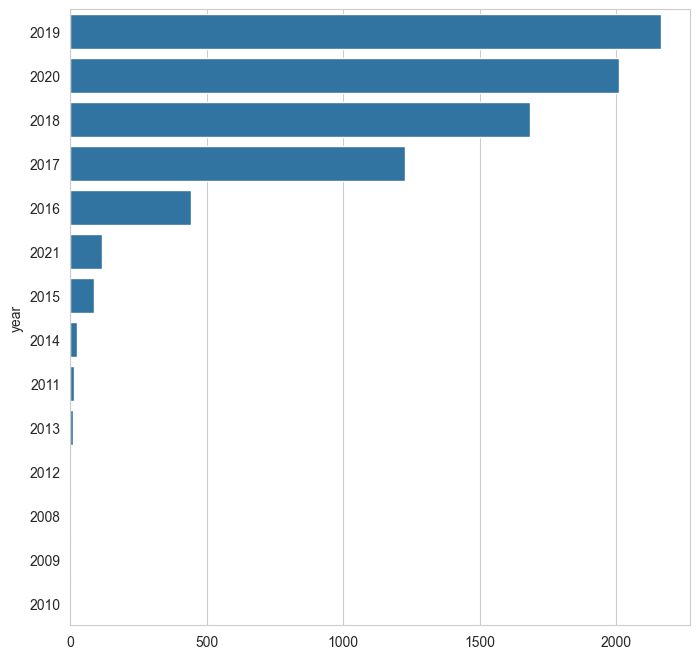

In [35]:
plt.figure(figsize=(8,8))

sns.barplot(x=x.values,y=x.index)

<Axes: xlabel='rating', ylabel='count'>

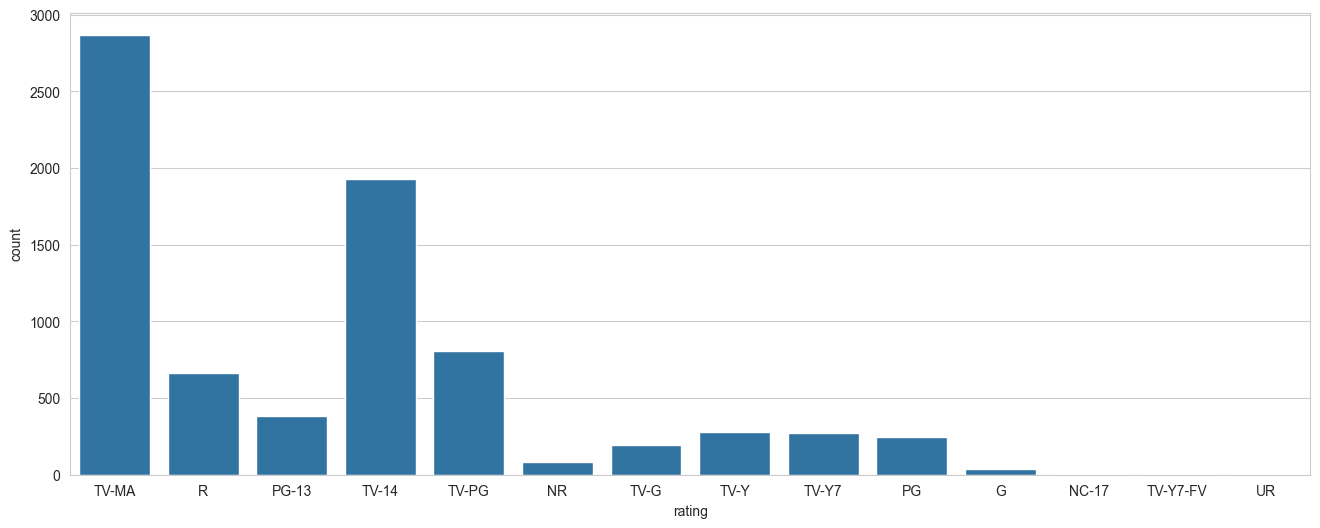

In [ ]:

plt.figure(figsize=(16,6))
sns.countplot(x= "rating",data= df)

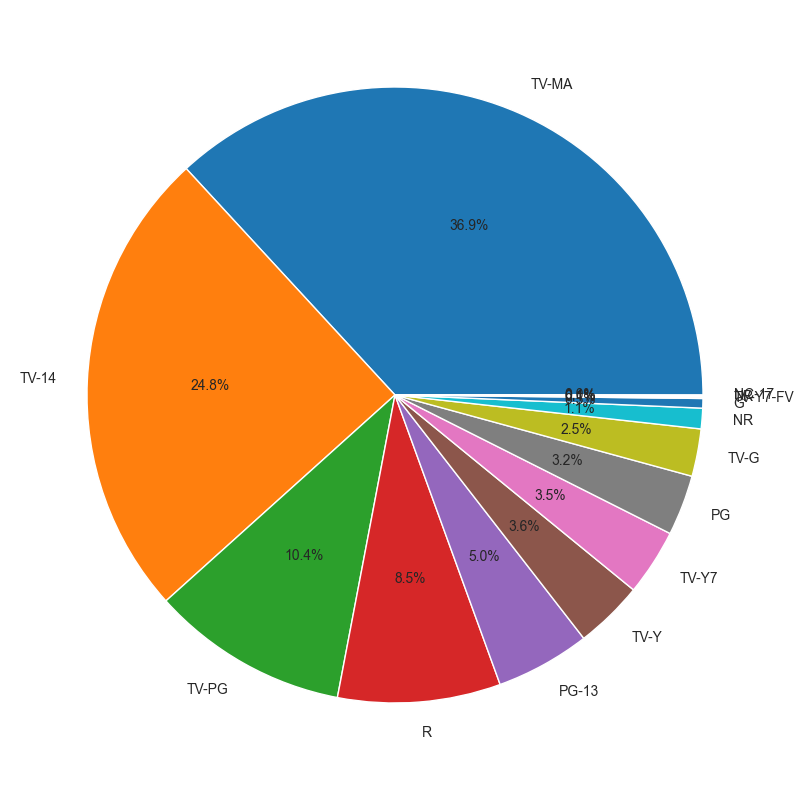

In [37]:
x= df.rating.value_counts()
plt.figure(figsize=(10,10))

labels= list(x.index)
plt.pie(x.values,labels= labels,autopct= "%1.1f%%")
plt.show()